# EDA & Preprocessing — CWRU Bearing Fault Detection
**Kelompok 4 | Peran: Data Engineer**
Mata Kuliah Machine Learning — D4 TRIN, Polman Bandung

**Tujuan notebook ini**
1. Memuat dan memahami dataset CWRU Bearing.
2. Eksplorasi data (EDA): kualitas data, distribusi kelas, distribusi fitur, korelasi, outlier.
3. Preprocessing & feature engineering.
4. Menghasilkan dataset bersih + `scaler.pkl` + `label_encoder.pkl` untuk ML Engineer dan Backend.

> **Catatan:** letakkan file CSV dataset Kaggle (`brjapon/cwru-bearing-datasets`) di folder `data/`
> Sel pertama otomatis menulis `preprocessing.py` (versi terbaru) di folder kerja, jadi cukup unggah notebook ini saja ke Colab.

In [1]:
%%writefile preprocessing.py
"""
preprocessing.py — Pipeline preprocessing dataset CWRU Bearing Fault Detection
Kelompok 4 | Peran: Data Engineer

Dataset (Kaggle: brjapon/cwru-bearing-datasets) berisi fitur statistik domain waktu
dari sinyal getaran: max, min, mean, sd, rms, skewness, kurtosis, crest, form
dan label `fault`.

Pemakaian (command line):
    python preprocessing.py --data_dir data --target fault

Pemakaian (dari notebook / app.py):
    from preprocessing import run_pipeline, transform_input
"""
import argparse
import glob
import json
import os
import re

import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_STATE = 42
BASE_FEATURES = ["max", "min", "mean", "sd", "rms", "skewness", "kurtosis", "crest", "form"]
ENGINEERED_FEATURES = ["peak_to_peak", "abs_peak", "energy", "sd_rms_ratio"]
TARGET_CANDIDATES = ["fault", "label", "class", "target"]
META_COLS = ["sampling_khz", "load_hp", "source_file"]
OUTPUT_FILES = {"cwru_clean.csv", "train_scaled.csv", "test_scaled.csv"}


# ---------------------------------------------------------------- 1. LOAD
def load_raw(data_dir):
    """Baca semua CSV di data_dir, gabungkan, tambahkan kolom metadata dari nama file."""
    files = sorted(
        f for f in glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True)
        if os.path.basename(f) not in OUTPUT_FILES
        and "processed" not in os.path.normpath(f).split(os.sep)
    )
    # Dataset CWRU di Kaggle berisi file fitur bernama "feature_time_*.csv".
    # Jika ada, hanya file itu yang dipakai (file CSV lain dilewati).
    feat_files = [f for f in files if "feature_time" in os.path.basename(f).lower()]
    files = feat_files or files
    if not files:
        raise FileNotFoundError(
            f"Tidak ada file .csv di folder '{data_dir}'. "
            "Unduh dataset dulu (lihat sel 'Unduh Dataset' di notebook) "
            "atau taruh file CSV Kaggle ke folder tersebut.")
    frames = []
    for f in files:
        df = pd.read_csv(f)
        df.columns = [str(c).strip().lower() for c in df.columns]
        df = df.loc[:, ~df.columns.str.startswith("unnamed")]
        name = os.path.basename(f)
        m_rate = re.search(r"(\d+)k", name)
        m_load = re.search(r"load[_-]?(\d+)", name)
        df["sampling_khz"] = int(m_rate.group(1)) if m_rate else np.nan
        df["load_hp"] = int(m_load.group(1)) if m_load else np.nan
        df["source_file"] = name
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def find_target(df):
    """Cari nama kolom label."""
    for c in TARGET_CANDIDATES:
        if c in df.columns:
            return c
    raise KeyError(f"Kolom target tidak ditemukan. Kolom tersedia: {list(df.columns)}")


# --------------------------------------------------------------- 2. CLEAN
def clean(df, target=None):
    """Hapus inf/NaN, duplikat, dan rapikan label."""
    target = target or find_target(df)
    df = df.copy()
    df = df.replace([np.inf, -np.inf], np.nan)
    feats = [c for c in BASE_FEATURES if c in df.columns]
    df = df.dropna(subset=feats + [target])
    df[target] = df[target].astype(str).str.strip()
    df = df.drop_duplicates(subset=feats + [target]).reset_index(drop=True)
    return df


def add_fault_type(df, target="fault"):
    """Turunkan kelompok kerusakan kasar: Normal / Ball / IR / OR dari label detail."""
    df = df.copy()
    prefix = df[target].str.split("_").str[0].str.strip()
    df["fault_type"] = prefix.where(prefix.isin(["Ball", "IR", "OR"]), "Normal")
    return df


# ----------------------------------------------------- 3. FEATURE ENGINEERING
def add_features(df):
    """Fitur turunan dari fitur statistik yang ada."""
    df = df.copy()
    eps = 1e-12
    df["peak_to_peak"] = df["max"] - df["min"]
    df["abs_peak"] = df[["max", "min"]].abs().max(axis=1)
    df["energy"] = df["rms"] ** 2
    df["sd_rms_ratio"] = df["sd"] / (df["rms"] + eps)
    return df


def get_feature_cols(df):
    return [c for c in BASE_FEATURES + ENGINEERED_FEATURES if c in df.columns]


# -------------------------------------------------- 4. SPLIT + SCALE + SAVE
def run_pipeline(data_dir="data", out_dir="data/processed", model_dir="models",
                 target="fault", test_size=0.2, save=True):
    """Pipeline lengkap. `target` bisa 'fault' (detail) atau 'fault_type' (4 kelas)."""
    raw = load_raw(data_dir)
    raw_target = find_target(raw)
    df = clean(raw, raw_target)
    if raw_target != "fault":
        df = df.rename(columns={raw_target: "fault"})
    df = add_fault_type(df, "fault")
    df = add_features(df)
    feats = get_feature_cols(df)

    X, y_text = df[feats], df[target]
    le = LabelEncoder().fit(y_text)
    y = le.transform(y_text)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=RANDOM_STATE)

    scaler = StandardScaler().fit(X_tr)  # fit hanya di data latih -> tanpa data leakage
    X_tr_s = pd.DataFrame(scaler.transform(X_tr), columns=feats, index=X_tr.index)
    X_te_s = pd.DataFrame(scaler.transform(X_te), columns=feats, index=X_te.index)

    result = dict(df_clean=df, features=feats, target=target, label_encoder=le,
                  scaler=scaler, X_train=X_tr_s, X_test=X_te_s, y_train=y_tr, y_test=y_te)

    if save:
        os.makedirs(out_dir, exist_ok=True)
        os.makedirs(model_dir, exist_ok=True)
        df.to_csv(os.path.join(out_dir, "cwru_clean.csv"), index=False)
        X_tr_s.assign(label=y_tr).to_csv(os.path.join(out_dir, "train_scaled.csv"), index=False)
        X_te_s.assign(label=y_te).to_csv(os.path.join(out_dir, "test_scaled.csv"), index=False)
        joblib.dump(scaler, os.path.join(model_dir, "scaler.pkl"))
        joblib.dump(le, os.path.join(model_dir, "label_encoder.pkl"))
        with open(os.path.join(model_dir, "feature_list.json"), "w") as fh:
            json.dump({"features": feats, "base_features": BASE_FEATURES,
                       "target": target, "classes": list(le.classes_)}, fh, indent=2)
    return result


# ------------------------------------------ 5. PREPROCESS INPUT DARI FORM WEB
def transform_input(values, model_dir="models"):
    """
    Ubah input form web (dict berisi 9 fitur dasar) menjadi array siap prediksi.
    Contoh: transform_input({"max": 0.2, "min": -0.2, ...})
    """
    scaler = joblib.load(os.path.join(model_dir, "scaler.pkl"))
    row = pd.DataFrame([{k: float(values[k]) for k in BASE_FEATURES}])
    row = add_features(row)
    feats = json.load(open(os.path.join(model_dir, "feature_list.json")))["features"]
    return scaler.transform(row[feats])


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default="data")
    ap.add_argument("--out_dir", default="data/processed")
    ap.add_argument("--model_dir", default="models")
    ap.add_argument("--target", default="fault", choices=["fault", "fault_type"])
    a = ap.parse_args()
    r = run_pipeline(a.data_dir, a.out_dir, a.model_dir, a.target)
    print("Fitur      :", r["features"])
    print("Kelas      :", list(r["label_encoder"].classes_))
    print("Data bersih:", r["df_clean"].shape)
    print("Train/Test :", r["X_train"].shape, r["X_test"].shape)

Writing preprocessing.py


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import importlib, preprocessing
importlib.reload(preprocessing)   # pastikan versi terbaru yang dipakai
from preprocessing import (load_raw, find_target, clean, add_fault_type, add_features,
                           run_pipeline, BASE_FEATURES, ENGINEERED_FEATURES)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR  = "data"     # folder berisi file CSV dari Kaggle
OUT_DIR   = "data/processed"   # lokasi dataset bersih (terpisah dari data mentah)
MODEL_DIR = "models"   # lokasi scaler & label encoder

## 0. Unduh Dataset (Google Colab / lokal)
Jalankan sel di bawah **satu kali**. Urutan percobaan: (1) cek folder `data/` sudah berisi CSV,
(2) unduh otomatis dari Kaggle dengan `kagglehub`, (3) jika gagal, unggah file CSV secara manual.

In [3]:
import glob, os, shutil, subprocess, sys

def _list_csv():
    return glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)

def ensure_data():
    """Pastikan folder DATA_DIR berisi CSV dataset. Aman dijalankan berulang kali."""
    os.makedirs(DATA_DIR, exist_ok=True)
    if _list_csv():
        return
    try:
        try:
            import kagglehub
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        path = kagglehub.dataset_download("brjapon/cwru-bearing-datasets")
        print("Dataset diunduh ke:", path)
        for root, _, names in os.walk(path):
            for n in names:
                if n.lower().endswith(".csv"):
                    shutil.copy(os.path.join(root, n), DATA_DIR)
    except Exception as e:
        print("Unduh otomatis gagal:", repr(e))
    if not _list_csv():
        try:
            from google.colab import files
            print("Silakan unggah file CSV dataset (boleh pilih banyak file)...")
            for nama in files.upload():
                shutil.move(nama, os.path.join(DATA_DIR, nama))
        except ImportError:
            pass
    if not _list_csv():
        raise FileNotFoundError(
            f"Masih tidak ada CSV di '{DATA_DIR}'. Unduh dataset dari Kaggle "
            "(brjapon/cwru-bearing-datasets) lalu unggah file CSV-nya ke folder tersebut.")

ensure_data()
print("File CSV ditemukan:", len(_list_csv()))
for f in sorted(_list_csv())[:15]:
    print(" -", f)

Using Colab cache for faster access to the 'cwru-bearing-datasets' dataset.
Dataset diunduh ke: /kaggle/input/cwru-bearing-datasets
File CSV ditemukan: 1
 - data/feature_time_48k_2048_load_1.csv


## 1. Memuat Data
Semua file CSV di `data/` digabung. Informasi *sampling rate* (kHz) dan *beban motor* (HP)
diambil dari nama file sebagai metadata (tidak dipakai sebagai fitur model agar tidak bocor).

In [4]:
ensure_data()
df_raw = load_raw(DATA_DIR)
TARGET = find_target(df_raw)
print("Ukuran data mentah :", df_raw.shape)
print("Kolom target       :", TARGET)
print("File sumber        :", df_raw["source_file"].nunique())
df_raw.head()

Ukuran data mentah : (2300, 13)
Kolom target       : fault
File sumber        : 1


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault,sampling_khz,load_hp,source_file
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv


## 2. Gambaran Umum Data

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2300 entries, 0 to 2299
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   max           2300 non-null   float64
 1   min           2300 non-null   float64
 2   mean          2300 non-null   float64
 3   sd            2300 non-null   float64
 4   rms           2300 non-null   float64
 5   skewness      2300 non-null   float64
 6   kurtosis      2300 non-null   float64
 7   crest         2300 non-null   float64
 8   form          2300 non-null   float64
 9   fault         2300 non-null   object 
 10  sampling_khz  2300 non-null   int64  
 11  load_hp       2300 non-null   int64  
 12  source_file   2300 non-null   object 
dtypes: float64(9), int64(2), object(2)
memory usage: 233.7+ KB


In [6]:
df_raw[BASE_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
max,2300.0,1.575079,1.578422,0.157300,0.456398,0.794510,2.278425,6.825900
min,2300.0,-1.550994,1.602706,-6.292600,-2.174975,-0.733700,-0.426987,-0.160220
mean,2300.0,0.015711,0.006469,0.003246,0.011236,0.013730,0.018638,0.038386
sd,2300.0,0.341601,0.305279,0.059140,0.135506,0.188551,0.555589,1.256577
rms,2300.0,0.342289,0.304813,0.061067,0.136374,0.190662,0.555671,1.256311
skewness,2300.0,-0.042251,0.180774,-1.089928,-0.103426,-0.002466,0.061093,1.059512
kurtosis,2300.0,2.664444,4.411096,-0.803795,-0.015164,0.816970,3.902286,30.385326
crest,2300.0,4.173130,1.148349,2.428511,3.260382,3.921650,4.815876,8.821577
form,2300.0,26.544769,29.209702,3.484429,7.413359,13.122811,39.911894,313.742612


## 3. Kualitas Data (Missing, Duplikat, Infinite)

In [7]:
feat_cols = [c for c in BASE_FEATURES if c in df_raw.columns]

quality = pd.DataFrame({
    "missing": df_raw[feat_cols + [TARGET]].isna().sum(),
    "infinite": np.isinf(df_raw[feat_cols]).sum().reindex(feat_cols + [TARGET]).fillna(0).astype(int),
})
print(quality)
print("\nBaris duplikat :", df_raw.duplicated(subset=feat_cols + [TARGET]).sum())
print("\nJumlah baris per file sumber:")
df_raw["source_file"].value_counts()

          missing  infinite
max             0         0
min             0         0
mean            0         0
sd              0         0
rms             0         0
skewness        0         0
kurtosis        0         0
crest           0         0
form            0         0
fault           0         0

Baris duplikat : 0

Jumlah baris per file sumber:


,count
source_file,
feature_time_48k_2048_load_1.csv,2300


## 4. Distribusi Kelas (Target)

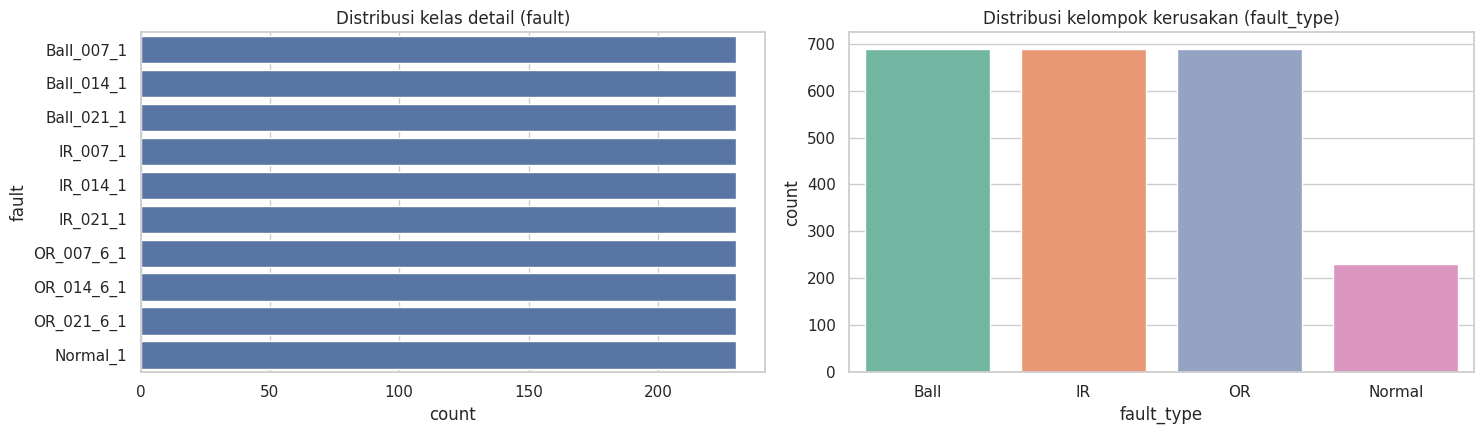

fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Normal_1      230
Name: count, dtype: int64

Rasio kelas terbesar : terkecil = 1.00 : 1


In [8]:
df_t = add_fault_type(df_raw.rename(columns={TARGET: "fault"}), "fault")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

order = df_raw[TARGET].value_counts().index
sns.countplot(data=df_raw, y=TARGET, order=order, ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribusi kelas detail (fault)")

if "fault_type" in df_t.columns:
    sns.countplot(data=df_t, x="fault_type", ax=ax[1], palette="Set2")
    ax[1].set_title("Distribusi kelompok kerusakan (fault_type)")
plt.tight_layout(); plt.show()

counts = df_raw[TARGET].value_counts()
print(counts)
print(f"\nRasio kelas terbesar : terkecil = {counts.max()/counts.min():.2f} : 1")

**Interpretasi:** jika rasio kelas mendekati 1 : 1, data seimbang dan akurasi aman dipakai sebagai metrik.
Jika timpang, rekomendasikan ke ML Engineer untuk memakai `class_weight='balanced'` dan metrik F1-macro.

## 5. Distribusi Fitur

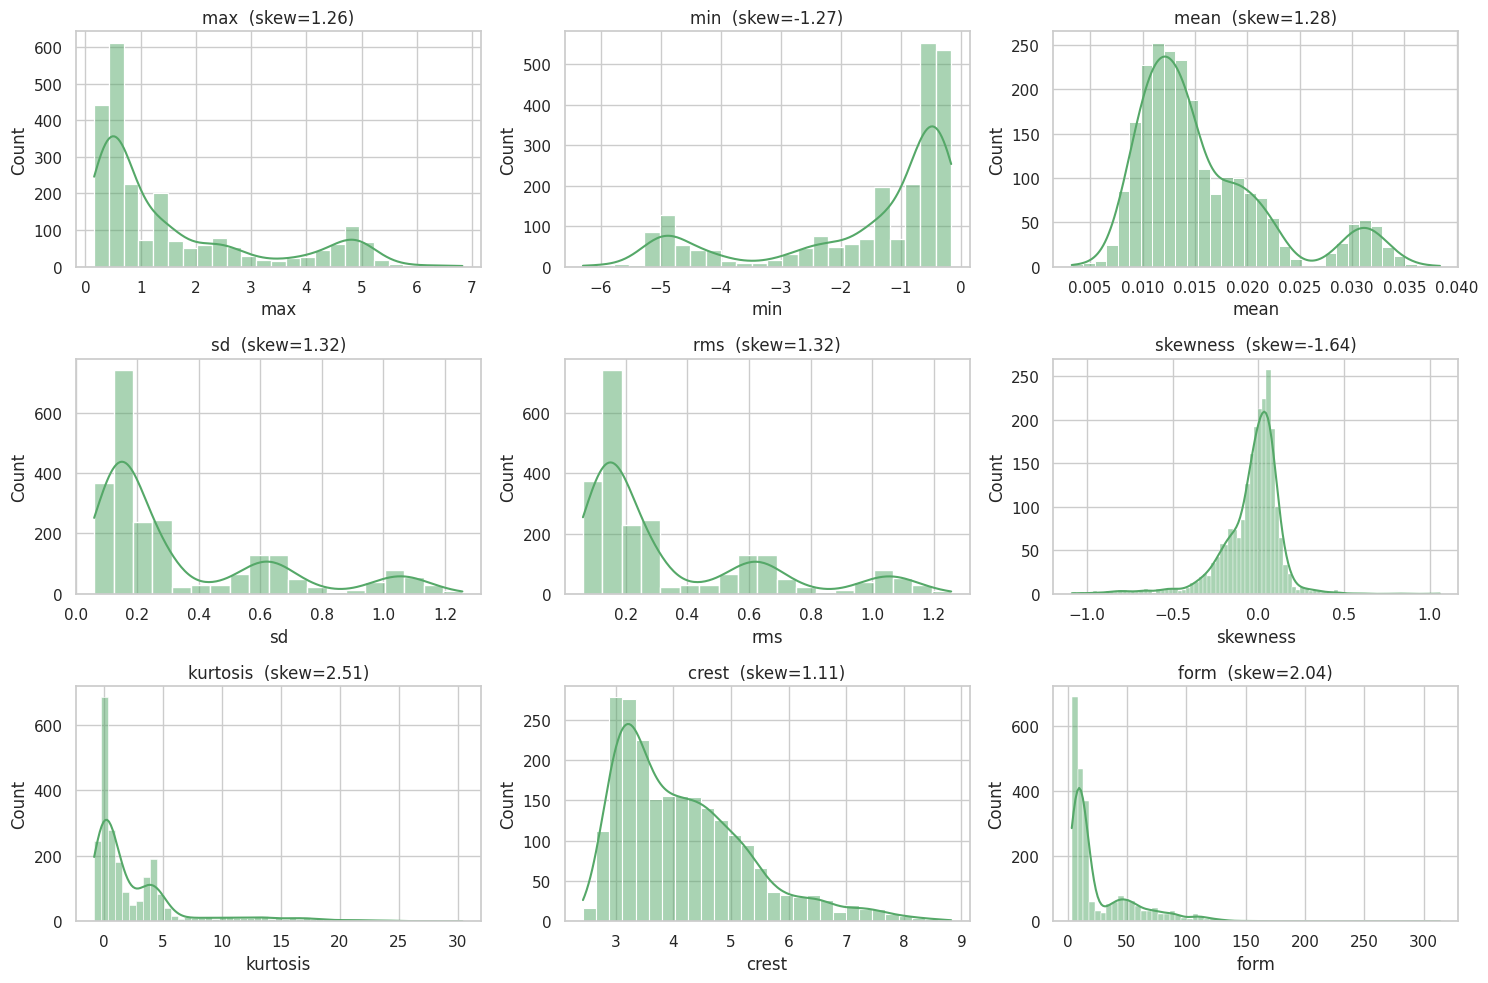

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(df_raw[c], kde=True, ax=ax, color="#55A868")
    ax.set_title(f"{c}  (skew={df_raw[c].skew():.2f})")
plt.tight_layout(); plt.show()

## 6. Fitur per Kelompok Kerusakan

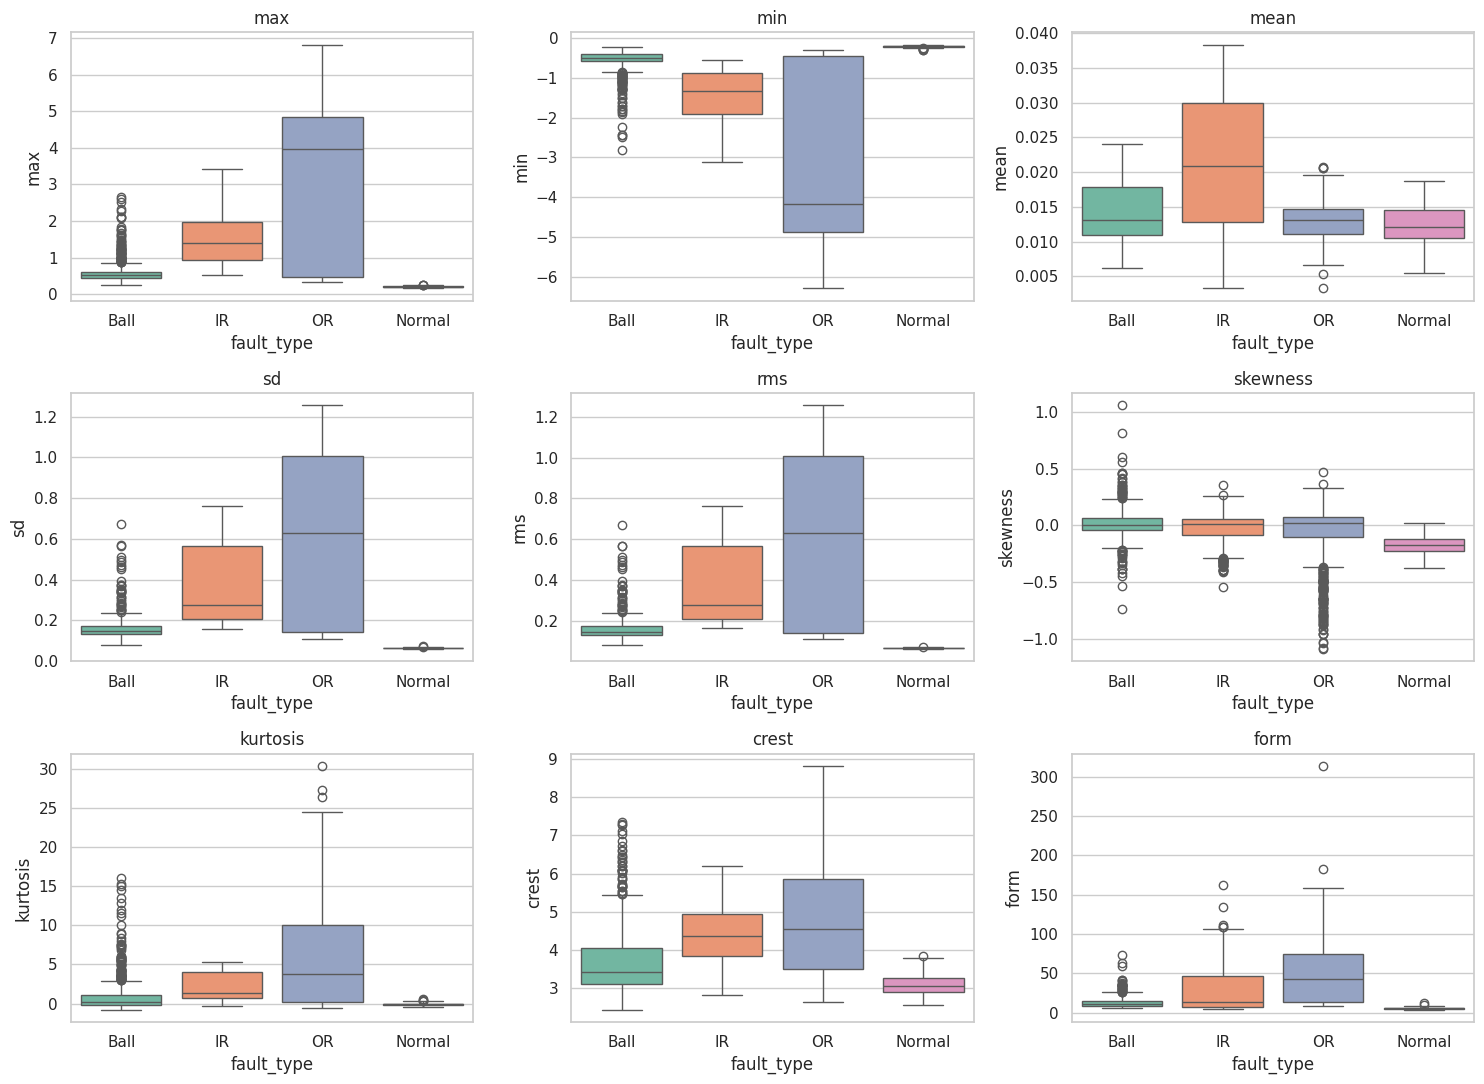

In [10]:
df_eda = add_fault_type(df_raw.rename(columns={TARGET: "fault"}), "fault")
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.boxplot(data=df_eda, x="fault_type", y=c, ax=ax, palette="Set2")
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Interpretasi:** fitur yang boxplot-nya berbeda jelas antar `fault_type` (misalnya `rms`, `kurtosis`, `crest`)
adalah kandidat fitur penting untuk model *supervised* maupun *clustering*.

## 7. Korelasi Antar Fitur

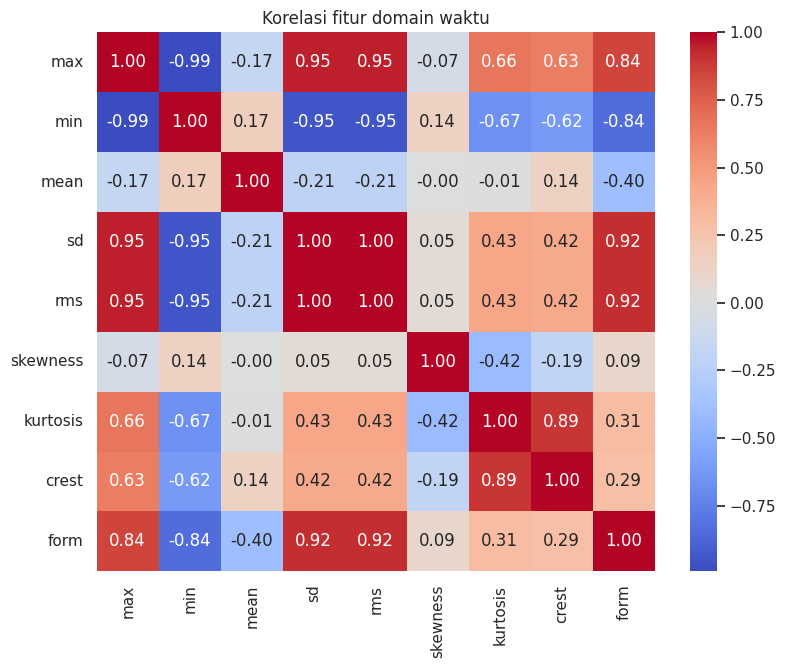

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_raw[feat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur domain waktu")
plt.show()

In [12]:
corr = df_raw[feat_cols].corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("Pasangan fitur berkorelasi tinggi (> 0.9):")
print(pairs[pairs > 0.9])

Pasangan fitur berkorelasi tinggi (> 0.9):
sd   rms     0.999998
max  min     0.992793
     sd      0.951709
     rms     0.951700
min  sd      0.947029
     rms     0.947007
sd   form    0.920629
rms  form    0.920397
dtype: float64


## 8. Deteksi Outlier (IQR)

In [13]:
rows = []
for c in feat_cols:
    q1, q3 = df_raw[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df_raw[c] < q1 - 1.5*iqr) | (df_raw[c] > q3 + 1.5*iqr)).sum()
    rows.append({"fitur": c, "jumlah_outlier": n, "persen": round(100*n/len(df_raw), 2)})
pd.DataFrame(rows).sort_values("persen", ascending=False)

,fitur,jumlah_outlier,persen
1,min,214,9.30
6,kurtosis,186,8.09
2,mean,182,7.91
5,skewness,139,6.04
8,form,122,5.30
0,max,84,3.65
7,crest,60,2.61
4,rms,11,0.48
3,sd,11,0.48


**Keputusan:** pada data getaran bearing, outlier umumnya **bukan error**, melainkan sinyal dari kerusakan
(impuls tinggi). Karena itu outlier **tidak dihapus**; kita memakai `StandardScaler` dan model berbasis pohon
yang cukup tahan terhadap outlier.

## 9. Pengaruh Beban Motor & Sampling Rate

In [14]:
if df_raw["load_hp"].notna().any():
    print(df_raw.groupby("load_hp")[["rms", "kurtosis", "crest"]].mean().round(4))
if df_raw["sampling_khz"].notna().any():
    print(df_raw.groupby("sampling_khz")[["rms", "kurtosis", "crest"]].mean().round(4))

            rms  kurtosis   crest
load_hp                          
1        0.3423    2.6644  4.1731
                 rms  kurtosis   crest
sampling_khz                          
48            0.3423    2.6644  4.1731


## 10. Cleaning & Feature Engineering
Langkah: hapus inf/NaN → hapus duplikat → turunkan `fault_type` → tambah fitur turunan:

| Fitur baru | Rumus | Makna |
|---|---|---|
| `peak_to_peak` | max − min | rentang amplitudo getaran |
| `abs_peak` | max(\|max\|, \|min\|) | amplitudo puncak mutlak |
| `energy` | rms² | energi sinyal |
| `sd_rms_ratio` | sd / rms | perbandingan fluktuasi terhadap level sinyal |

In [15]:
df_clean = clean(df_raw, TARGET)
if TARGET != "fault":
    df_clean = df_clean.rename(columns={TARGET: "fault"})
df_clean = add_fault_type(df_clean, "fault")
df_clean = add_features(df_clean)

print(f"Sebelum cleaning : {len(df_raw):,} baris")
print(f"Sesudah cleaning : {len(df_clean):,} baris  (dibuang {len(df_raw)-len(df_clean):,})")
df_clean.head()

Sebelum cleaning : 2,300 baris
Sesudah cleaning : 2,300 baris  (dibuang 0)


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault,sampling_khz,load_hp,source_file,fault_type,peak_to_peak,abs_peak,energy,sd_rms_ratio
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv,Ball,0.77876,0.41890,0.015378,0.989839
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv,Ball,0.82883,0.46772,0.018040,0.986418
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv,Ball,0.90664,0.46855,0.022803,0.991011
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv,Ball,1.12778,0.58475,0.025097,0.991451
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1,48,1,feature_time_48k_2048_load_1.csv,Ball,1.02576,0.57891,0.019578,0.987612


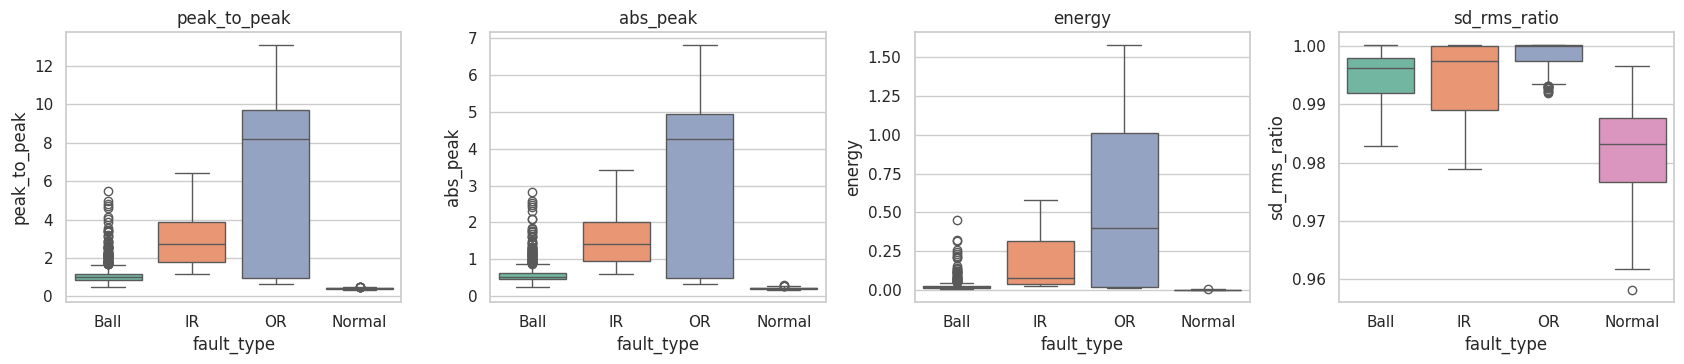

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, ENGINEERED_FEATURES):
    sns.boxplot(data=df_clean, x="fault_type", y=c, ax=ax, palette="Set2")
    ax.set_title(c)
plt.tight_layout(); plt.show()

## 11. Split, Scaling, dan Penyimpanan Artefak
- Split **80 : 20** dengan **stratified** (proporsi kelas terjaga), `random_state=42`.
- `StandardScaler` di-*fit* hanya pada data latih (mencegah *data leakage*).
- Menyimpan: `cwru_clean.csv`, `train_scaled.csv`, `test_scaled.csv`, `scaler.pkl`, `label_encoder.pkl`, `feature_list.json`.

In [17]:
# Ganti ke "fault_type" bila tim memilih klasifikasi 4 kelas (Normal/Ball/IR/OR)
res = run_pipeline(DATA_DIR, OUT_DIR, MODEL_DIR, target="fault", test_size=0.2)

print("Fitur   :", res["features"])
print("Kelas   :", list(res["label_encoder"].classes_))
print("Train   :", res["X_train"].shape, "| Test:", res["X_test"].shape)

Fitur   : ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'peak_to_peak', 'abs_peak', 'energy', 'sd_rms_ratio']
Kelas   : ['Ball_007_1', 'Ball_014_1', 'Ball_021_1', 'IR_007_1', 'IR_014_1', 'IR_021_1', 'Normal_1', 'OR_007_6_1', 'OR_014_6_1', 'OR_021_6_1']
Train   : (1840, 13) | Test: (460, 13)


In [18]:
# Cek: distribusi kelas train vs test harus mirip (stratified)
chk = pd.DataFrame({
    "train_%": pd.Series(res["y_train"]).value_counts(normalize=True).sort_index() * 100,
    "test_%":  pd.Series(res["y_test"]).value_counts(normalize=True).sort_index() * 100,
}).round(2)
chk.index = res["label_encoder"].inverse_transform(chk.index)
chk

,train_%,test_%
Ball_007_1,10.0,10.0
Ball_014_1,10.0,10.0
Ball_021_1,10.0,10.0
IR_007_1,10.0,10.0
IR_014_1,10.0,10.0
IR_021_1,10.0,10.0
Normal_1,10.0,10.0
OR_007_6_1,10.0,10.0
OR_014_6_1,10.0,10.0
OR_021_6_1,10.0,10.0


## 12. Visualisasi Keterpisahan Kelas (PCA 2D)

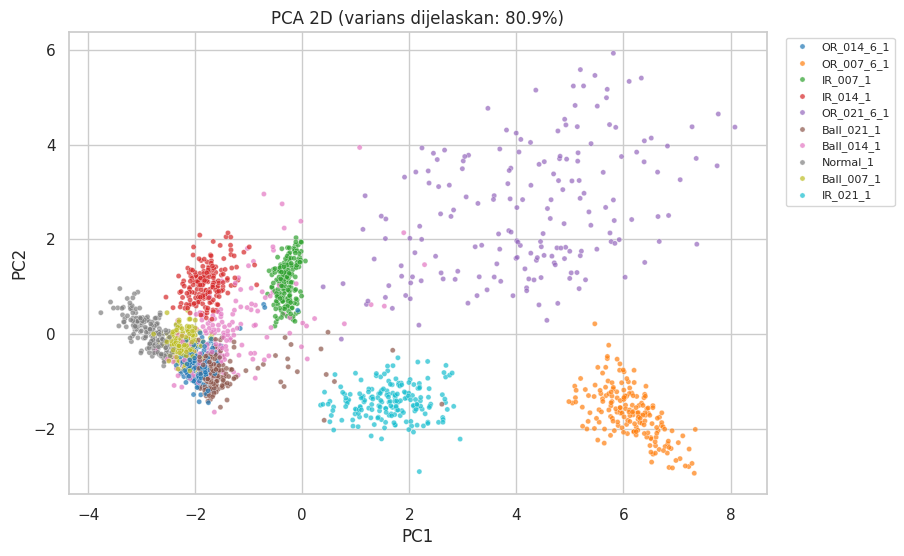

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(res["X_train"])
labels = res["label_encoder"].inverse_transform(res["y_train"])

plt.figure(figsize=(9, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=labels, s=14, alpha=0.7, palette="tab10")
plt.title(f"PCA 2D (varians dijelaskan: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.show()

**Interpretasi:** kelas yang terpisah jelas di PCA mudah diklasifikasikan; kelas yang menumpuk berpotensi tertukar
pada model *supervised* dan menjadi insight untuk *clustering* (Unsupervised).

## 13. Verifikasi Artefak untuk Tim

In [20]:
import os, joblib, json

for f in ["cwru_clean.csv", "train_scaled.csv", "test_scaled.csv"]:
    p = os.path.join(OUT_DIR, f); print(f"{p:<28} {os.path.getsize(p)/1024:,.0f} KB")
for f in ["scaler.pkl", "label_encoder.pkl", "feature_list.json"]:
    p = os.path.join(MODEL_DIR, f); print(f"{p:<28} {os.path.getsize(p)/1024:,.1f} KB")

scaler = joblib.load(os.path.join(MODEL_DIR, "scaler.pkl"))
print("\nScaler memuat", scaler.n_features_in_, "fitur ->", json.load(open(os.path.join(MODEL_DIR, "feature_list.json")))["features"])

data/processed/cwru_clean.csv 562 KB
data/processed/train_scaled.csv 463 KB
data/processed/test_scaled.csv 116 KB
models/scaler.pkl            1.2 KB
models/label_encoder.pkl     0.6 KB
models/feature_list.json     0.5 KB

Scaler memuat 13 fitur -> ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'peak_to_peak', 'abs_peak', 'energy', 'sd_rms_ratio']


## 14. Kesimpulan & Handoff ke Tim

**Temuan utama** *(isi ulang sesuai hasil nyata setelah notebook dijalankan)*:
- Jumlah data bersih: ...  | Jumlah kelas: ...  | Rasio ketimpangan kelas: ...
- Fitur paling membedakan kelas: ... (lihat boxplot & PCA)
- Fitur berkorelasi tinggi: ... (pertimbangkan seleksi fitur)
- Outlier dipertahankan karena merepresentasikan kerusakan.

**Handoff:**
| Untuk | File | Catatan |
|---|---|---|
| ML Engineer 1 & 2 | `data/processed/train_scaled.csv`, `data/processed/test_scaled.csv` | kolom `label` = target ter-encode |
| ML Engineer 1 & 2 | `models/label_encoder.pkl` | `inverse_transform` untuk nama kelas |
| Backend Dev | `preprocessing.transform_input()` + `models/scaler.pkl` + `feature_list.json` | memproses input form web |